In [2]:
pip install ultralytics

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 833.4/833.4 kB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.4/56.4 MB 73.3 MB/s eta 0:00:000m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━ 4/5 [ultralytics]  WARNING: The scripts ultralytics and yolo are installed in '/home/f15c/.local/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [ultralytics]
Note: you may need to restart the kernel to use updated packages.


In [10]:
from ultralytics import YOLO
import time
import os

YOLO11_MODEL = "yolo11n.pt"

YOLO11_PROJECT = "/home/f15c/H/runs/detect/YOLO_Experiments"

YOLO11_RUN_NAME = "YOLO11n_Plastic_Shampoo_Bottle"

YOLO11_RESULTS_DIR = os.path.join(
    YOLO11_PROJECT,
    YOLO11_RUN_NAME
)

print(YOLO11_RESULTS_DIR)

/home/f15c/H/runs/detect/YOLO_Experiments/YOLO11n_Plastic_Shampoo_Bottle


In [2]:
start_time = time.time()

model = YOLO(YOLO11_MODEL)

results = model.train(
    data="/home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    workers=4,
    device=0,
    project=YOLO11_PROJECT,
    name=YOLO11_RUN_NAME
)

YOLO11_TRAIN_TIME = (
    time.time() - start_time
) / 60

print(
    f"Training Time = {YOLO11_TRAIN_TIME:.2f} minutes"
)

Ultralytics 8.4.73 🚀 Python-3.12.11 torch-2.8.0+cu129 CUDA:0 (NVIDIA GeForce RTX 2080 SUPER, 7783MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11n_Plastic_Shampoo_Bottle, nbs=64, nms=False, opset=None

In [11]:
import pandas as pd

results_csv = os.path.join(
    YOLO11_RESULTS_DIR,
    "results.csv"
)

yolo11_results = pd.read_csv(results_csv)

print(yolo11_results.columns)

yolo11_results.head()

Index(['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss',
       'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)',
       'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss',
       'lr/pg0', 'lr/pg1', 'lr/pg2'],
      dtype='object')


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,50.3934,2.39985,3.50982,1.54364,0.40993,0.43543,0.37749,0.14101,2.15408,2.41614,1.45733,0.000237,0.000237,0.000237
1,2,90.5482,2.12292,2.07637,1.39394,0.51390,0.52928,0.47818,0.18189,2.06826,2.01337,1.40069,0.000471,0.000471,0.000471
2,3,129.8880,2.07724,1.79915,1.38620,0.50745,0.57013,0.54310,0.21351,2.06748,1.88993,1.44395,0.000699,0.000699,0.000699
3,4,168.5220,2.04275,1.61865,1.37149,0.58772,0.66973,0.62347,0.25802,1.96707,1.51079,1.36511,0.000693,0.000693,0.000693
4,5,210.1580,1.99529,1.50827,1.34399,0.62191,0.68452,0.66370,0.27924,1.95300,1.40368,1.35174,0.000686,0.000686,0.000686


In [12]:
final_epoch = yolo11_results.iloc[-1]

YOLO11_PRECISION = final_epoch["metrics/precision(B)"]

YOLO11_RECALL = final_epoch["metrics/recall(B)"]

YOLO11_MAP50 = final_epoch["metrics/mAP50(B)"]

YOLO11_F1 = (
    2 * YOLO11_PRECISION * YOLO11_RECALL
) / (
    YOLO11_PRECISION + YOLO11_RECALL + 1e-8
)

print("Precision :", YOLO11_PRECISION)

print("Recall    :", YOLO11_RECALL)

print("F1        :", YOLO11_F1)

print("mAP50     :", YOLO11_MAP50)


Precision : 0.79072
Recall    : 0.84579
F1        : 0.8173284180522673
mAP50     : 0.85909


In [5]:
best_model = os.path.join(
    YOLO11_RESULTS_DIR,
    "weights",
    "best.pt"
)

model = YOLO(best_model)

test_metrics = model.val(
    data="/home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml",
    split="test"
)

print(test_metrics)

Ultralytics 8.4.76 🚀 Python-3.12.11 torch-2.8.0+cu129 CUDA:0 (NVIDIA GeForce RTX 2080 SUPER, 7783MiB)
YOLO11n summary (fused): 101 layers, 2,584,102 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5.1±0.2 MB/s, size: 21.1 KB)
val: Scanning /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/test/labels.cache... 790 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 790/790 157.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 15.5it/s 3.2s0.1s
                   all        790       2920      0.783      0.864      0.863       0.44
         adhesion_marg         46         93      0.657       0.71      0.781      0.407
        adhesion_unacc         85        199       0.95      0.995      0.983       0.75
             dent_marg        106        387      0.912      0.914      0.932      0.425
            dent_unacc         99        315       0.62      0.889      0.791      0.314


In [6]:
YOLO11_TEST_PRECISION = test_metrics.box.mp

YOLO11_TEST_RECALL = test_metrics.box.mr

YOLO11_TEST_MAP50 = test_metrics.box.map50

YOLO11_TEST_F1 = (
    2 * YOLO11_TEST_PRECISION * YOLO11_TEST_RECALL
) / (
    YOLO11_TEST_PRECISION +
    YOLO11_TEST_RECALL +
    1e-8
)

print("TEST Precision =", YOLO11_TEST_PRECISION)

print("TEST Recall =", YOLO11_TEST_RECALL)

print("TEST F1 =", YOLO11_TEST_F1)

print("TEST mAP50 =", YOLO11_TEST_MAP50)


TEST Precision = 0.7833124295241053
TEST Recall = 0.8639397933053516
TEST F1 = 0.8216528895446117
TEST mAP50 = 0.8630318881110947


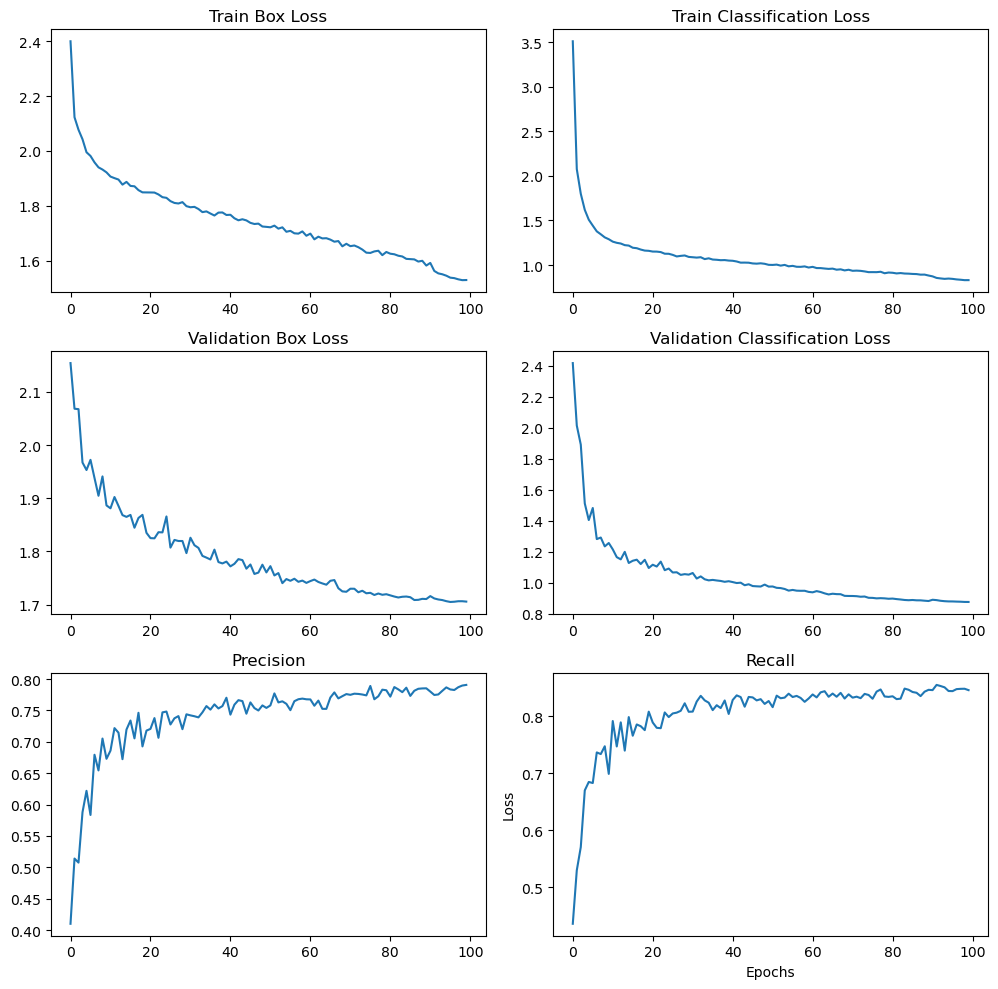

In [15]:
import matplotlib.pyplot as plt
%matplotlib inline

fig, axes = plt.subplots(
    3,
    2,
    figsize=(10,10)
)

# Train Box Loss
axes[0,0].plot(
    yolo11_results["train/box_loss"]
)
axes[0,0].set_title(
    "Train Box Loss"
)
plt.xlabel("Epochs")
plt.ylabel("Loss")

# Train Class Loss
axes[0,1].plot(
    yolo11_results["train/cls_loss"]
)
axes[0,1].set_title(
    "Train Classification Loss"
)
plt.xlabel("Epochs")
plt.ylabel("Loss")

# Validation Box Loss
axes[1,0].plot(
    yolo11_results["val/box_loss"]
)
axes[1,0].set_title(
    "Validation Box Loss"
)
plt.xlabel("Epochs")
plt.ylabel("Loss")

# Validation Class Loss
axes[1,1].plot(
    yolo11_results["val/cls_loss"]
)
axes[1,1].set_title(
    "Validation Classification Loss"
)
plt.xlabel("Epochs")
plt.ylabel("Loss")

# Precision
axes[2,0].plot(
    yolo11_results["metrics/precision(B)"]
)
axes[2,0].set_title(
    "Precision"
)
plt.xlabel("Epochs")
plt.ylabel("Loss")

# Recall
axes[2,1].plot(
    yolo11_results["metrics/recall(B)"]
)
axes[2,1].set_title(
    "Recall"
)
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.tight_layout()

plt.show()

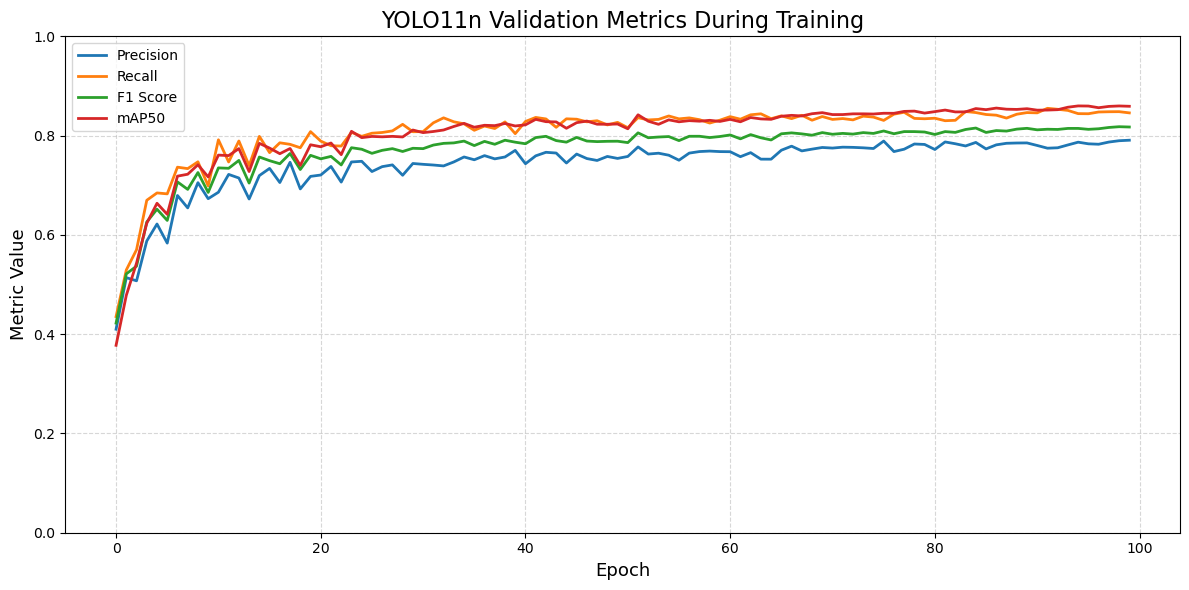

In [19]:
plt.figure(figsize=(12,6))

plt.plot(
    yolo11_results["metrics/precision(B)"],
    label="Precision",
    linewidth=2
)

plt.plot(
    yolo11_results["metrics/recall(B)"],
    label="Recall",
    linewidth=2
)

# Compute F1 for every epoch
f1 = (
    2
    * yolo11_results["metrics/precision(B)"]
    * yolo11_results["metrics/recall(B)"]
) / (
    yolo11_results["metrics/precision(B)"]
    + yolo11_results["metrics/recall(B)"]
    + 1e-8
)

plt.plot(
    f1,
    label="F1 Score",
    linewidth=2
)

plt.plot(
    yolo11_results["metrics/mAP50(B)"],
    label="mAP50",
    linewidth=2
)

plt.title("YOLO11n Validation Metrics During Training", fontsize=16)
plt.xlabel("Epoch", fontsize=13)
plt.ylabel("Metric Value", fontsize=13)

plt.ylim(0.0, 1.0)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

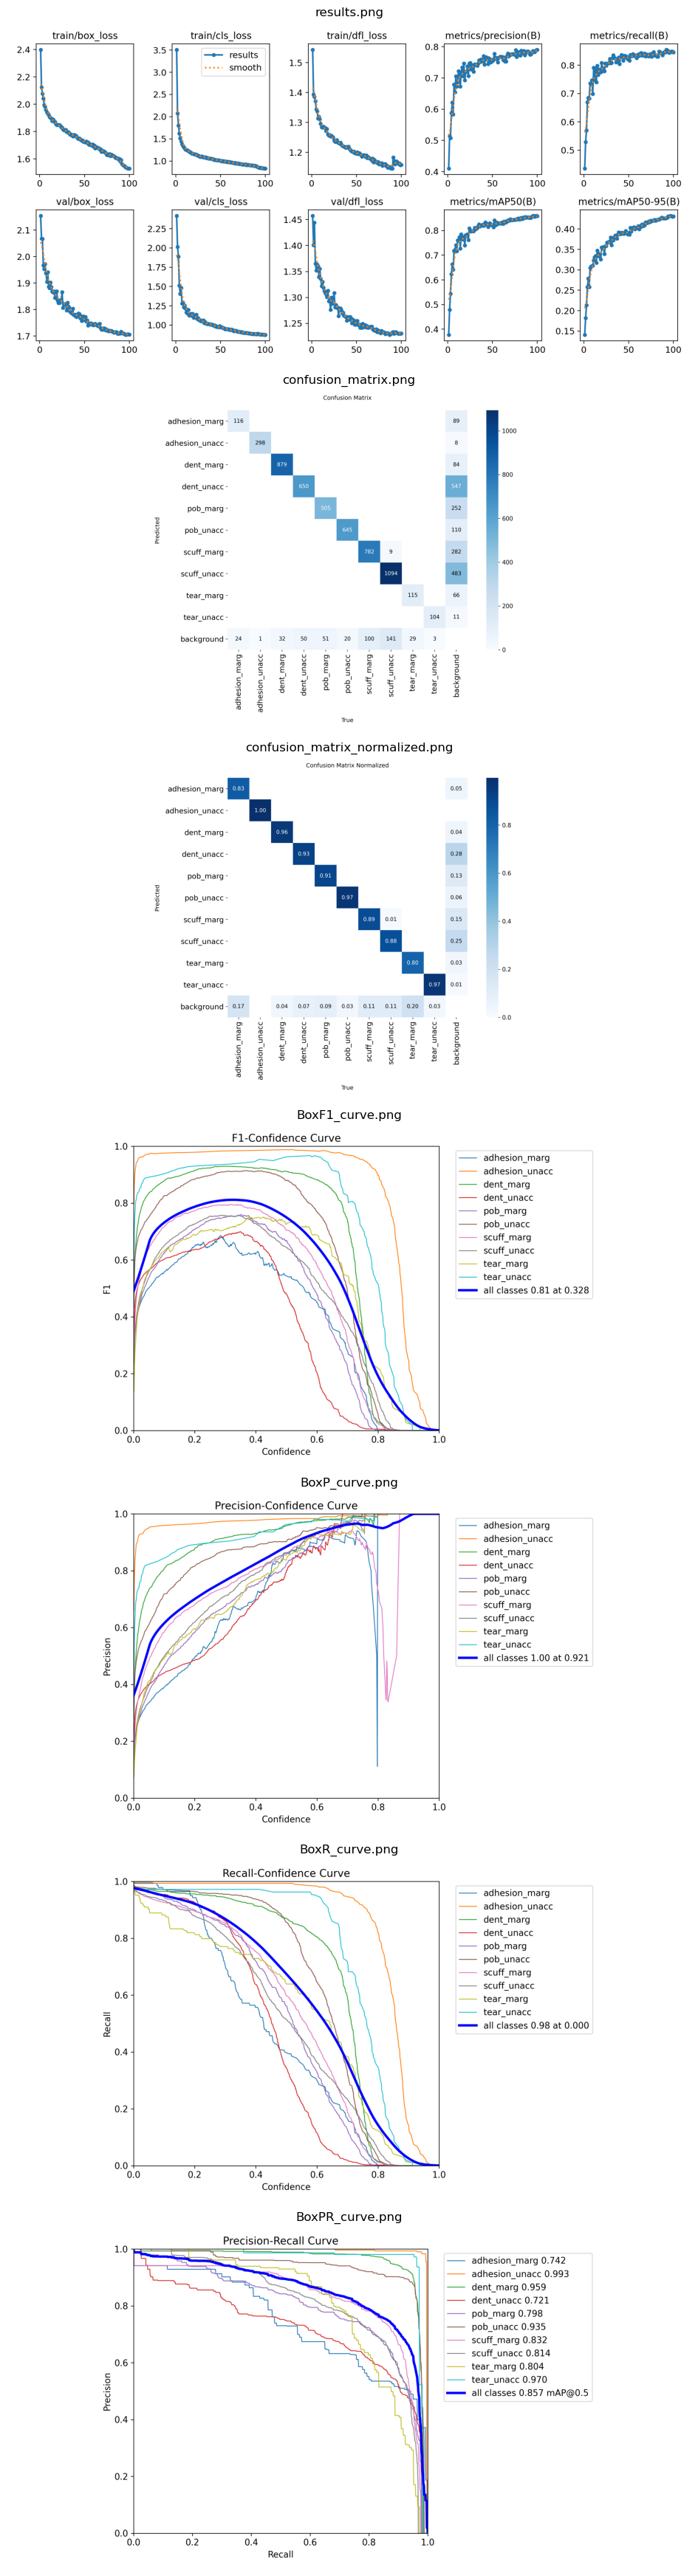

In [10]:
from PIL import Image
import matplotlib.pyplot as plt
%matplotlib inline

plot_files = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "BoxPR_curve.png"
]

fig, axes = plt.subplots(
    len(plot_files),
    1,
    figsize=(10,35)
)

for ax, plot in zip(axes, plot_files):

    img_path = os.path.join(
        YOLO11_RESULTS_DIR,
        plot
    )

    if os.path.exists(img_path):

        img = Image.open(img_path)

        ax.imshow(img)

        ax.set_title(plot)

        ax.axis("off")

plt.tight_layout()

plt.show()

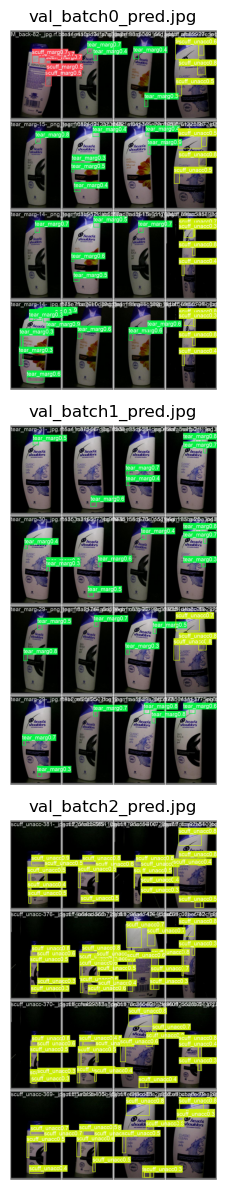

In [11]:
sample_images = [
    "val_batch0_pred.jpg",
    "val_batch1_pred.jpg",
    "val_batch2_pred.jpg"
]

fig, axes = plt.subplots(
    len(sample_images),
    1,
    figsize=(12,12)
)

for ax, img_name in zip(
    axes,
    sample_images
):

    img_path = os.path.join(
        YOLO11_RESULTS_DIR,
        img_name
    )

    if os.path.exists(img_path):

        img = Image.open(img_path)

        ax.imshow(img)

        ax.set_title(img_name)

        ax.axis("off")

plt.tight_layout()

plt.show()

In [12]:
YOLO11_RESULTS = {
    "Model": "YOLO11n",
    "Precision": YOLO11_TEST_PRECISION,
    "Recall": YOLO11_TEST_RECALL,
    "F1": YOLO11_TEST_F1,
    "mAP50": YOLO11_TEST_MAP50,
    "mAP50-95": YOLO11_TEST_MAP5095,
    "Training_Time_Min": YOLO11_TRAIN_TIME
}

YOLO11_RESULTS

{'Model': 'YOLO11n',
 'Precision': 0.7833124295241053,
 'Recall': 0.8639397933053516,
 'F1': 0.8216528895446117,
 'mAP50': 0.8630318881110947,
 'mAP50-95': 0.439585370896655,
 'Training_Time_Min': 66.17873974641164}